<a href="https://colab.research.google.com/github/KP-365/hybrid-ope-lending/blob/main/H4_rolling_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H4: rolling out-of-time comparison

**Question:** on years a model has never seen, does XGBoost beat logistic regression and the constant baseline, and how fast does each get worse?

**Design:** fit once on 2007 to 2010, then score 2011, 2012, 2013 and 2014 (1 to 4 years ahead). `year` is not a feature here, because the test is about unseen years. Propensity XGBoost uses Model 1 settings, outcome XGBoost uses Model 2 settings. Logistic regression leaves out `zip3`.

## 0. Imports and data

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/hybrid-ope-lending'
combined = pd.read_parquet(f'{DATA_DIR}/lending_club_combined.parquet')
outcome_df = pd.read_parquet(f'{DATA_DIR}/lending_club_outcome.parquet')

# propensity data: shared features + 'accepted' label ; outcome data: shared features + 'default' label
X_features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state']
features_combined = X_features + ['accepted', 'year']
features_outcome = X_features + ['default', 'year']
y_feature_comb = 'accepted'
y_feature_out = 'default'

comb = combined[features_combined].copy()
out = outcome_df[features_outcome].copy()

# Same preparation as Model 1 and Model 2. Without this, XGBoost can pick up the FICO-midpoint
# fingerprint (accepted scores end in 2 or 7) and the propensity results look too good.
comb = comb[comb['risk_score'].notna()].copy()       # Model 1 used scored applicants only: an unscored applicant is almost always rejected (a shortcut)
comb['risk_score'] = comb['risk_score'] // 5 * 5
out = out[out['risk_score'].notna()].copy()          # Model 2 used scored rows only
out['risk_score'] = out['risk_score'] // 5 * 5

# training window and test years
years = [2011, 2012, 2013, 2014]
comb_dataset_2007_10 = comb[(comb['year'] >= 2007) & (comb['year'] <= 2010)]
out_dataset_2007_10 = out[(out['year'] >= 2007) & (out['year'] <= 2010)]


Mounted at /content/drive


In [ ]:
# Sanity checks before modelling
print('training rows  comb:', len(comb_dataset_2007_10), ' out:', len(out_dataset_2007_10))
print('rows per year  comb:'); print(comb['year'].value_counts().sort_index().loc[2007:2014])
print('rows per year  out:');  print(out['year'].value_counts().sort_index().loc[2007:2014])
print('risk_score is banded (every value a multiple of 5):', bool(((comb['risk_score'].dropna() % 5) == 0).all()), bool(((out['risk_score'].dropna() % 5) == 0).all()))
print(comb[X_features].dtypes)   # purpose and state should be 'category' for XGBoost
print('missing share  comb:'); print(comb_dataset_2007_10[X_features].isna().mean().round(3))


training rows  comb: 190083  out: 20814
rows per year  comb:
year
2007       5549
2008      24433
2009      52699
2010     107402
2011     216748
2012     367161
2013     835292
2014    1911862
Name: count, dtype: int64
rows per year  out:
year
2007       603
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    100422
2014    162570
Name: count, dtype: int64
risk_score is banded (every value a multiple of 5): True True
amount         float64
purpose       category
risk_score     float64
dti            float64
zip3          category
state         category
dtype: object
missing share  comb:
amount        0.000
purpose       0.000
risk_score    0.000
dti           0.026
zip3          0.000
state         0.000
dtype: float64


## 1. Models

In [ ]:
# propensity (comb) uses Model 1 settings, outcome (out) uses Model 2 settings
xgb_comb_model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
xgb_out_model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                                  max_depth=3, learning_rate=0.05, min_child_weight=50)
logres_comb_model = LogisticRegression(max_iter=1000)
logres_out_model = LogisticRegression(max_iter=1000)


## 2. Logistic regression needs numbers only, and everything is fitted once on 2007 to 2010

In [ ]:
num_cols = ['amount', 'risk_score', 'dti']
cat_cols = ['purpose', 'state']          # zip3 left out (because there are hundreds of values) does not benifit LR, say so in the write-up

def get_stats(train_df):
    # numbers learned from the TRAINING years only
    return {'median': train_df[num_cols].median(),
            'mean': train_df[num_cols].mean(),
            'std': train_df[num_cols].std()}

def make_logres_data(df, stats, dummy_cols=None):
    x = df[num_cols + cat_cols].copy()
    # 1) "was missing" flags
    x['risk_score_missing'] = x['risk_score'].isna().astype(int)
    x['dti_missing'] = x['dti'].isna().astype(int)
    # 2) fill missing numbers with the training median, then scale
    for c in num_cols:
        x[c] = (x[c].fillna(stats['median'][c]) - stats['mean'][c]) / stats['std'][c]
    # 3) one-hot the categories (as text)
    for c in cat_cols:
        x[c] = x[c].astype(str)
    x = pd.get_dummies(x, columns=cat_cols, dtype=int)
    # 4) make the columns match the training columns (unseen categories become all zeros)
    if dummy_cols is not None:
        x = x.reindex(columns=dummy_cols, fill_value=0)
    return x

# fit everything on the training years (2007 to 2010) ONCE
comb_stats = get_stats(comb_dataset_2007_10)
out_stats = get_stats(out_dataset_2007_10)

comb_train_x = make_logres_data(comb_dataset_2007_10, comb_stats)
out_train_x = make_logres_data(out_dataset_2007_10, out_stats)
comb_dummy_cols = list(comb_train_x.columns)
out_dummy_cols = list(out_train_x.columns)

xgb_comb_model.fit(comb_dataset_2007_10[X_features], comb_dataset_2007_10[y_feature_comb])
logres_comb_model.fit(comb_train_x, comb_dataset_2007_10[y_feature_comb])
xgb_out_model.fit(out_dataset_2007_10[X_features], out_dataset_2007_10[y_feature_out])
logres_out_model.fit(out_train_x, out_dataset_2007_10[y_feature_out])

# baseline numbers (training rates)
comb_train_rate = comb_dataset_2007_10[y_feature_comb].mean()
out_train_rate = out_dataset_2007_10[y_feature_out].mean()


## 3. Propensity model on each unseen year

In [ ]:
n_rows_comb = []
base_logloss_comb = []
xgb_logloss_comb = []
logres_logloss_comb = []
xgb_meanpred_comb = []
logres_meanpred_comb = []
actual_rate_comb = []

for year in years:
    comb_dataset = comb[comb['year'] == year]
    y_true = comb_dataset[y_feature_comb]

    base = np.full(len(comb_dataset), comb_train_rate)
    xgb_p = xgb_comb_model.predict_proba(comb_dataset[X_features])[:, 1]
    logres_p = logres_comb_model.predict_proba(
        make_logres_data(comb_dataset, comb_stats, comb_dummy_cols))[:, 1]

    n_rows_comb.append(len(comb_dataset))
    base_logloss_comb.append(log_loss(y_true, base, labels=[0, 1]))
    xgb_logloss_comb.append(log_loss(y_true, xgb_p, labels=[0, 1]))
    logres_logloss_comb.append(log_loss(y_true, logres_p, labels=[0, 1]))
    xgb_meanpred_comb.append(xgb_p.mean())
    logres_meanpred_comb.append(logres_p.mean())
    actual_rate_comb.append(y_true.mean())


## 4. Outcome model on each unseen year

In [ ]:
n_rows_out = []
base_logloss_out = []
xgb_logloss_out = []
logres_logloss_out = []
xgb_meanpred_out = []
logres_meanpred_out = []
actual_rate_out = []

for year in years:
    out_dataset = out[out['year'] == year]
    y_true = out_dataset[y_feature_out]

    base = np.full(len(out_dataset), out_train_rate)
    xgb_p = xgb_out_model.predict_proba(out_dataset[X_features])[:, 1]
    logres_p = logres_out_model.predict_proba(
        make_logres_data(out_dataset, out_stats, out_dummy_cols))[:, 1]

    n_rows_out.append(len(out_dataset))
    base_logloss_out.append(log_loss(y_true, base, labels=[0, 1]))
    xgb_logloss_out.append(log_loss(y_true, xgb_p, labels=[0, 1]))
    logres_logloss_out.append(log_loss(y_true, logres_p, labels=[0, 1]))
    xgb_meanpred_out.append(xgb_p.mean())
    logres_meanpred_out.append(logres_p.mean())
    actual_rate_out.append(y_true.mean())


## 5. Tables and plots

Read each model against the baseline in the same year, and compare `mean_pred` with `actual_rate`.

PROPENSITY
 year  n_rows  baseline  xgboost  logreg  xgb_mean_pred  logreg_mean_pred  actual_rate
 2011  216748    0.3260   0.2254  0.2324         0.0981            0.1018       0.1002
 2012  367161    0.4206   0.4051  0.3294         0.1019            0.0943       0.1454
 2013  835292    0.4542   0.4950  0.3816         0.1004            0.0928       0.1614
 2014 1911862    0.3743   0.4486  0.3286         0.0861            0.0900       0.1232
OUTCOME
 year  n_rows  baseline  xgboost  logreg  xgb_mean_pred  logreg_mean_pred  actual_rate
 2011   21721    0.4258   0.4240  0.4111         0.1491            0.1484       0.1518
 2012   53367    0.4434   0.4491  0.4313         0.1653            0.1711       0.1620
 2013  100422    0.3764   0.3932  0.3814         0.1725            0.1776       0.1233
 2014  162570    0.4007   0.4161  0.4014         0.1727            0.1755       0.1373


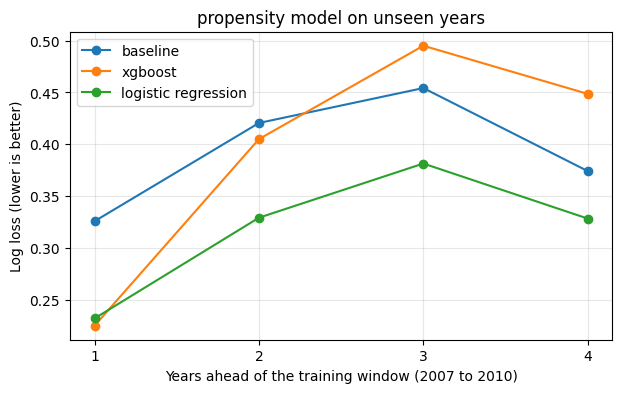

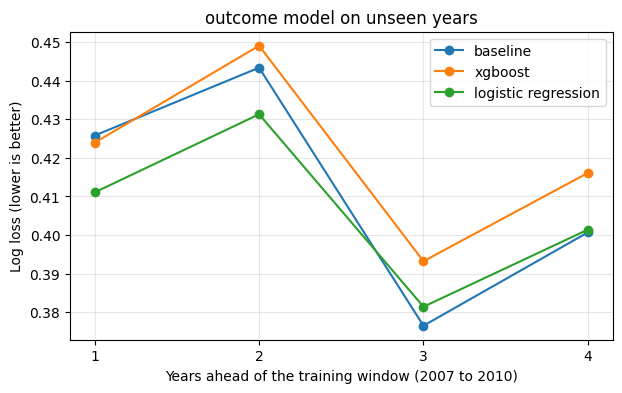

In [ ]:
comb_table = pd.DataFrame({'year': years, 'n_rows': n_rows_comb,
                           'baseline': base_logloss_comb, 'xgboost': xgb_logloss_comb,
                           'logreg': logres_logloss_comb,
                           'xgb_mean_pred': xgb_meanpred_comb, 'logreg_mean_pred': logres_meanpred_comb,
                           'actual_rate': actual_rate_comb})
out_table = pd.DataFrame({'year': years, 'n_rows': n_rows_out,
                          'baseline': base_logloss_out, 'xgboost': xgb_logloss_out,
                          'logreg': logres_logloss_out,
                          'xgb_mean_pred': xgb_meanpred_out, 'logreg_mean_pred': logres_meanpred_out,
                          'actual_rate': actual_rate_out})
print('PROPENSITY'); print(comb_table.round(4).to_string(index=False))
print('OUTCOME');    print(out_table.round(4).to_string(index=False))

for name, table in [('propensity', comb_table), ('outcome', out_table)]:
    plt.figure(figsize=(7, 4))
    plt.plot(table['year'] - 2010, table['baseline'], marker='o', label='baseline')
    plt.plot(table['year'] - 2010, table['xgboost'], marker='o', label='xgboost')
    plt.plot(table['year'] - 2010, table['logreg'], marker='o', label='logistic regression')
    plt.xlabel('Years ahead of the training window (2007 to 2010)')
    plt.ylabel('Log loss (lower is better)')
    plt.title(name + ' model on unseen years')
    plt.xticks([1, 2, 3, 4])
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


## 6. Long window: train 2007 to 2013, test 2014

The first test used a small training window (2007 to 2010), which favours the simple model. This one gives every model a long window and asks for one year ahead. `xgboost_with_year` shows whether giving XGBoost the year helps or hurts on an unseen year.

In [ ]:
# train on 2007 to 2013, test on 2014 (one year ahead, long window)
comb_train_long = comb[comb['year'] <= 2013]
comb_test = comb[comb['year'] == 2014]
out_train_long = out[out['year'] <= 2013]
out_test = out[out['year'] == 2014]
print('rows  comb train:', len(comb_train_long), ' test:', len(comb_test))
print('rows  out  train:', len(out_train_long), ' test:', len(out_test))

# models (same settings as before). The extra XGBoost gets 'year' as a feature, to see if it helps or hurts on an unseen year.
xgb_comb_long = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
xgb_comb_long_year = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
logres_comb_long = LogisticRegression(max_iter=1000)
xgb_out_long = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                                 max_depth=3, learning_rate=0.05, min_child_weight=50)
xgb_out_long_year = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                                      max_depth=3, learning_rate=0.05, min_child_weight=50)
logres_out_long = LogisticRegression(max_iter=1000)

# logistic regression data: numbers learned from the 2007 to 2013 rows only
comb_stats_long = get_stats(comb_train_long)
out_stats_long = get_stats(out_train_long)
comb_train_x_long = make_logres_data(comb_train_long, comb_stats_long)
out_train_x_long = make_logres_data(out_train_long, out_stats_long)
comb_cols_long = list(comb_train_x_long.columns)
out_cols_long = list(out_train_x_long.columns)

# fit once
xgb_comb_long.fit(comb_train_long[X_features], comb_train_long[y_feature_comb])
xgb_comb_long_year.fit(comb_train_long[X_features + ['year']], comb_train_long[y_feature_comb])
logres_comb_long.fit(comb_train_x_long, comb_train_long[y_feature_comb])
xgb_out_long.fit(out_train_long[X_features], out_train_long[y_feature_out])
xgb_out_long_year.fit(out_train_long[X_features + ['year']], out_train_long[y_feature_out])
logres_out_long.fit(out_train_x_long, out_train_long[y_feature_out])

# predictions on 2014 (each computed once)
comb_y = comb_test[y_feature_comb]
comb_base = np.full(len(comb_test), comb_train_long[y_feature_comb].mean())
comb_xgb_p = xgb_comb_long.predict_proba(comb_test[X_features])[:, 1]
comb_xgb_year_p = xgb_comb_long_year.predict_proba(comb_test[X_features + ['year']])[:, 1]
comb_logres_p = logres_comb_long.predict_proba(make_logres_data(comb_test, comb_stats_long, comb_cols_long))[:, 1]

out_y = out_test[y_feature_out]
out_base = np.full(len(out_test), out_train_long[y_feature_out].mean())
out_xgb_p = xgb_out_long.predict_proba(out_test[X_features])[:, 1]
out_xgb_year_p = xgb_out_long_year.predict_proba(out_test[X_features + ['year']])[:, 1]
out_logres_p = logres_out_long.predict_proba(make_logres_data(out_test, out_stats_long, out_cols_long))[:, 1]

# results table
long_table = pd.DataFrame({
    'dataset': ['propensity'] * 4 + ['outcome'] * 4,
    'model': ['baseline', 'xgboost', 'xgboost_with_year', 'logreg'] * 2,
    'logloss': [log_loss(comb_y, comb_base, labels=[0, 1]), log_loss(comb_y, comb_xgb_p, labels=[0, 1]),
                log_loss(comb_y, comb_xgb_year_p, labels=[0, 1]), log_loss(comb_y, comb_logres_p, labels=[0, 1]),
                log_loss(out_y, out_base, labels=[0, 1]), log_loss(out_y, out_xgb_p, labels=[0, 1]),
                log_loss(out_y, out_xgb_year_p, labels=[0, 1]), log_loss(out_y, out_logres_p, labels=[0, 1])],
    'mean_pred': [comb_base.mean(), comb_xgb_p.mean(), comb_xgb_year_p.mean(), comb_logres_p.mean(),
                  out_base.mean(), out_xgb_p.mean(), out_xgb_year_p.mean(), out_logres_p.mean()],
    'actual_rate': [comb_y.mean()] * 4 + [out_y.mean()] * 4,
})
print(long_table.round(4).to_string(index=False))


rows  comb train: 1609284  test: 1911862
rows  out  train: 196324  test: 162570
   dataset             model  logloss  mean_pred  actual_rate
propensity          baseline   0.3751     0.1434       0.1232
propensity           xgboost   0.2008     0.1189       0.1232
propensity xgboost_with_year   0.1959     0.1276       0.1232
propensity            logreg   0.3100     0.1305       0.1232
   outcome          baseline   0.4000     0.1398       0.1373
   outcome           xgboost   0.3917     0.1465       0.1373
   outcome xgboost_with_year   0.3907     0.1307       0.1373
   outcome            logreg   0.3896     0.1465       0.1373


## 7. Calibration where the probabilities are small (propensity, 2014)

IPS weights are 1/p. For each bucket of predicted p, compare the average prediction with the real acceptance rate. If a model predicts 0.02 where the real rate is 0.001, the weights are 20 times too small.

In [ ]:
# Calibration in the small-probability region (propensity model, 2014).
# IPS weights are 1/p, so a p that is too big or too small here changes the weights a lot.
bins = [0, 0.001, 0.01, 0.05, 0.2, 0.5, 1.0]
for name, p in [('xgboost', comb_xgb_p), ('logreg', comb_logres_p)]:
    t = pd.DataFrame({'p': p, 'y': comb_y.values})
    t['bucket'] = pd.cut(t['p'], bins=bins, include_lowest=True)
    summary = t.groupby('bucket', observed=True).agg(n=('y', 'size'),
                                                     mean_pred=('p', 'mean'),
                                                     actual_rate=('y', 'mean'))
    print(name); print(summary.round(4)); print()


xgboost
                       n  mean_pred  actual_rate
bucket                                          
(-0.001, 0.001]  1182239     0.0000       0.0029
(0.001, 0.01]      97545     0.0033       0.0030
(0.01, 0.05]       54669     0.0281       0.0609
(0.05, 0.2]       156316     0.1219       0.1743
(0.2, 0.5]        241608     0.3371       0.3317
(0.5, 1.0]        179485     0.6956       0.6754

logreg
                      n  mean_pred  actual_rate
bucket                                         
(-0.001, 0.001]   80433     0.0003       0.0000
(0.001, 0.01]    260518     0.0050       0.0002
(0.01, 0.05]     494755     0.0271       0.0100
(0.05, 0.2]      646645     0.1106       0.1312
(0.2, 0.5]       342459     0.3065       0.3619
(0.5, 1.0]        87052     0.6693       0.2512



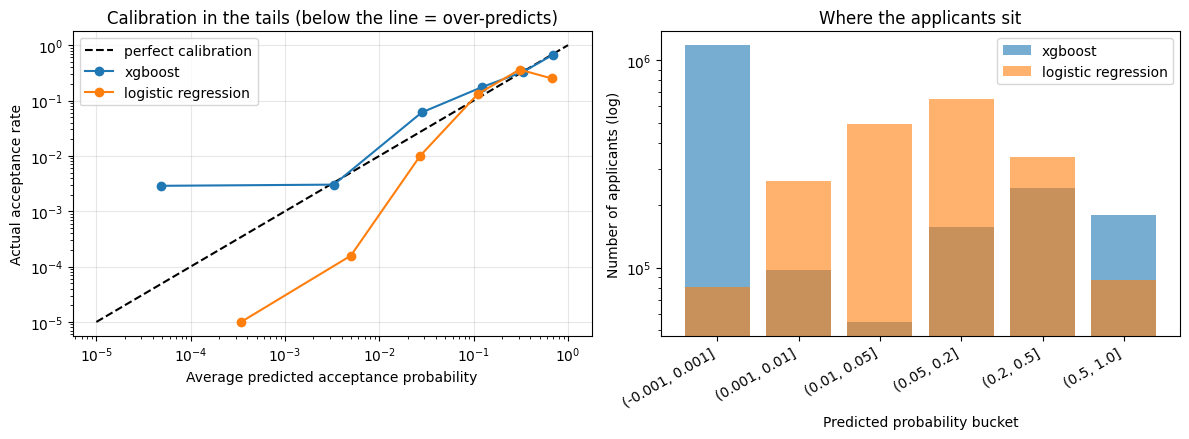

In [ ]:
bins = [0, 0.001, 0.01, 0.05, 0.2, 0.5, 1.0]
floor = 1e-5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot([floor, 1], [floor, 1], 'k--', label='perfect calibration')

for name, p in [('xgboost', comb_xgb_p), ('logistic regression', comb_logres_p)]:
    t = pd.DataFrame({'p': p, 'y': comb_y.values})
    t['bucket'] = pd.cut(t['p'], bins=bins, include_lowest=True)
    s = t.groupby('bucket', observed=True).agg(n=('y', 'size'),
                                               mean_pred=('p', 'mean'),
                                               actual=('y', 'mean'))
    ax1.plot(s['mean_pred'].clip(lower=floor), s['actual'].clip(lower=floor),
             marker='o', label=name)
    ax2.bar([str(b) for b in s.index], s['n'], alpha=0.6, label=name)

ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel('Average predicted acceptance probability')
ax1.set_ylabel('Actual acceptance rate')
ax1.set_title('Calibration in the tails (below the line = over-predicts)')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.set_yscale('log')
ax2.set_xlabel('Predicted probability bucket')
ax2.set_ylabel('Number of applicants (log)')
ax2.set_title('Where the applicants sit')
ax2.legend()
plt.setp(ax2.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

xgboost
                       n  mean_pred  actual_rate  actual_accepted  expected_accepted  ratio_expected_to_actual
bucket                                                                                                        
(-0.001, 0.001]  1182239     0.0000       0.0029             3405            57.7937                    0.0170
(0.001, 0.01]      97545     0.0033       0.0030              295           320.7385                    1.0872
(0.01, 0.05]       54669     0.0281       0.0609             3331          1538.0227                    0.4617
(0.05, 0.2]       156316     0.1219       0.1743            27239         19052.2987                    0.6994
(0.2, 0.5]        241608     0.3371       0.3317            80137         81458.1246                    1.0165
(0.5, 1.0]        179485     0.6956       0.6754           121222        124853.0241                    1.0300

logistic regression
                      n  mean_pred  actual_rate  actual_accepted  expected_accepted

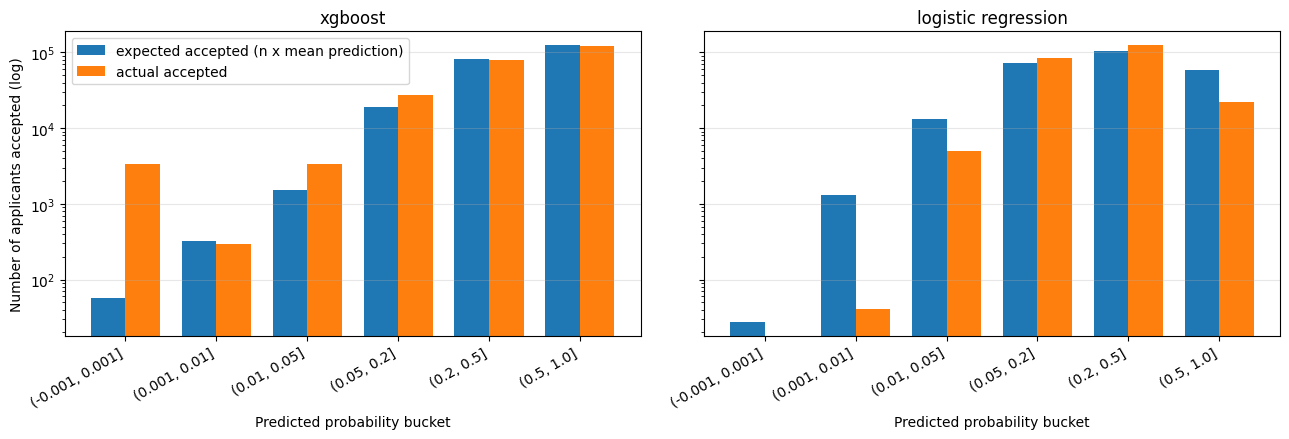

In [ ]:
bins = [0, 0.001, 0.01, 0.05, 0.2, 0.5, 1.0]

tables = {}
for name, p in [('xgboost', comb_xgb_p), ('logistic regression', comb_logres_p)]:
    t = pd.DataFrame({'p': p, 'y': comb_y.values})
    t['bucket'] = pd.cut(t['p'], bins=bins, include_lowest=True)
    s = t.groupby('bucket', observed=True).agg(n=('y', 'size'),
                                               mean_pred=('p', 'mean'),
                                               actual_rate=('y', 'mean'),
                                               actual_accepted=('y', 'sum'))
    s['expected_accepted'] = s['n'] * s['mean_pred']
    s['ratio_expected_to_actual'] = s['expected_accepted'] / s['actual_accepted']
    tables[name] = s
    print(name)
    print(s.round(4).to_string())
    print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (name, s) in zip(axes, tables.items()):
    x = np.arange(len(s))
    w = 0.38
    ax.bar(x - w/2, s['expected_accepted'], w, label='expected accepted (n x mean prediction)')
    ax.bar(x + w/2, s['actual_accepted'], w, label='actual accepted')
    ax.set_xticks(x)
    ax.set_xticklabels([str(b) for b in s.index], rotation=30, ha='right')
    ax.set_yscale('log')
    ax.set_title(name)
    ax.set_xlabel('Predicted probability bucket')
    ax.grid(alpha=0.3, axis='y')
axes[0].set_ylabel('Number of applicants accepted (log)')
axes[0].legend()
plt.tight_layout()
plt.show()